# DEcision tree to predict bank customer churning
A decision tree, to predict if a Customer will continue to be a customer of a bank based on the present conditions 

['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']

In [2]:
!pip install pydotplus


In [4]:
from sklearn import tree #For our Decision Tree
import pandas as pd # For our DataFrame
import pydotplus # To create our Decision Tree Graph
import six #utility functions for smoothing over the differences between the Python versions
import sys
sys.modules['sklearn.externals.six'] = six

from IPython.display import Image 
from sklearn.tree import export_graphviz
from IPython.display import Image

In [18]:
df = pd.read_csv('Bank_Customers.csv', index_col=0)

In [20]:
df

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
RowNumber,,,,,,,,,,,,,
1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1


In [36]:
#df = df.set_index(df.index[0])
unique_values = df['Geography'].unique()

In [38]:
print(unique_values)

['France' 'Spain' 'Germany']


In [24]:
df.describe()

,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [28]:
df.dtypes

CustomerId           int64
Surname             object
CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

In [30]:
df['HasCrCard'] = df['HasCrCard'].astype(bool)

In [32]:
df['IsActiveMember'] = df['IsActiveMember'].astype(bool)

In [34]:
df.dtypes


CustomerId           int64
Surname             object
CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard             bool
IsActiveMember        bool
EstimatedSalary    float64
Exited               int64
dtype: object

## Using our intelligence 
Here based on the column names, I guess we can make a decision to ignore surname and customer ID for the decision we are making. 
We can perform one_hot_encoding on geography and gender before proceeding. 


In [41]:
one_hot_data = pd.get_dummies(df[ ['Geography','Gender'] ])

In [43]:
one_hot_data

,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male
RowNumber,,,,,
1,True,False,False,True,False
2,False,False,True,True,False
3,True,False,False,True,False
4,True,False,False,True,False
5,False,False,True,True,False
...,...,...,...,...,...
9996,True,False,False,False,True
9997,True,False,False,False,True
9998,True,False,False,True,False


In [47]:
#bankpd.merge(df, one_hot_data, on='RowNumber'))
df.merge(one_hot_data, on = 'RowNumber')

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male
RowNumber,,,,,,,,,,,,,,,,,,
1,15634602,Hargrave,619,France,Female,42,2,0.00,1,True,True,101348.88,1,True,False,False,True,False
2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,False,True,112542.58,0,False,False,True,True,False
3,15619304,Onio,502,France,Female,42,8,159660.80,3,True,False,113931.57,1,True,False,False,True,False
4,15701354,Boni,699,France,Female,39,1,0.00,2,False,False,93826.63,0,True,False,False,True,False
5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,True,True,79084.10,0,False,False,True,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,True,False,96270.64,0,True,False,False,False,True
9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,True,True,101699.77,0,True,False,False,False,True
9998,15584532,Liu,709,France,Female,36,7,0.00,1,False,True,42085.58,1,True,False,False,True,False


In [49]:
#df = df.drop('Geopraghy', axis=1)
#df = df.drop('Gender', axis=1)
#df = df.drop('Surname', axis=1)
df.drop(columns=['Geography', 'Gender' , 'Surname','CustomerId'], axis = 1, inplace = True )

In [51]:
df

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
RowNumber,,,,,,,,,
1,619,42,2,0.00,1,True,True,101348.88,1
2,608,41,1,83807.86,1,False,True,112542.58,0
3,502,42,8,159660.80,3,True,False,113931.57,1
4,699,39,1,0.00,2,False,False,93826.63,0
5,850,43,2,125510.82,1,True,True,79084.10,0
...,...,...,...,...,...,...,...,...,...
9996,771,39,5,0.00,2,True,False,96270.64,0
9997,516,35,10,57369.61,1,True,True,101699.77,0
9998,709,36,7,0.00,1,False,True,42085.58,1


In [55]:
df1 = df.merge(one_hot_data, on = 'RowNumber')

In [59]:
df1.drop('Exited', axis=1, inplace = True)

In [61]:
full_Y=df['Exited']

In [63]:
full_X = df1

In [65]:
full_X

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male
RowNumber,,,,,,,,,,,,,
1,619,42,2,0.00,1,True,True,101348.88,True,False,False,True,False
2,608,41,1,83807.86,1,False,True,112542.58,False,False,True,True,False
3,502,42,8,159660.80,3,True,False,113931.57,True,False,False,True,False
4,699,39,1,0.00,2,False,False,93826.63,True,False,False,True,False
5,850,43,2,125510.82,1,True,True,79084.10,False,False,True,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9996,771,39,5,0.00,2,True,False,96270.64,True,False,False,False,True
9997,516,35,10,57369.61,1,True,True,101699.77,True,False,False,False,True
9998,709,36,7,0.00,1,False,True,42085.58,True,False,False,True,False


In [67]:
full_Y

RowNumber
1        1
2        0
3        1
4        0
5        0
        ..
9996     0
9997     0
9998     1
9999     1
10000    0
Name: Exited, Length: 10000, dtype: int64

In [69]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(full_X,full_Y,test_size=0.2,random_state=20)

In [71]:
X_test.shape

(2000, 13)

In [73]:
X_train.shape

(8000, 13)

# Entropy- Information Gain

In [78]:
clf_ent = tree.DecisionTreeClassifier(criterion="entropy")
# Training the Decision Tree
clf_ent_train = clf_ent.fit(X_train, y_train)

In [80]:
clf_ent_train

DecisionTreeClassifier(criterion='entropy')

In [82]:
print(tree.export_graphviz(clf_ent_train, None))

digraph Tree {
node [shape=box, fontname="helvetica"] ;
edge [fontname="helvetica"] ;
0 [label="x[1] <= 42.5\nentropy = 0.737\nsamples = 8000\nvalue = [6340, 1660]"] ;
1 [label="x[4] <= 2.5\nentropy = 0.523\nsamples = 5670\nvalue = [5003, 667]"] ;
0 -> 1 [labeldistance=2.5, labelangle=45, headlabel="True"] ;
2 [label="x[4] <= 1.5\nentropy = 0.481\nsamples = 5545\nvalue = [4970, 575]"] ;
1 -> 2 ;
3 [label="x[9] <= 0.5\nentropy = 0.651\nsamples = 2720\nvalue = [2265.0, 455.0]"] ;
2 -> 3 ;
4 [label="x[3] <= 68072.797\nentropy = 0.569\nsamples = 2050\nvalue = [1775, 275]"] ;
3 -> 4 ;
5 [label="x[11] <= 0.5\nentropy = 0.787\nsamples = 532\nvalue = [407, 125]"] ;
4 -> 5 ;
6 [label="x[0] <= 419.0\nentropy = 0.668\nsamples = 292\nvalue = [241, 51]"] ;
5 -> 6 ;
7 [label="entropy = 0.0\nsamples = 5\nvalue = [0, 5]"] ;
6 -> 7 ;
8 [label="x[0] <= 830.5\nentropy = 0.635\nsamples = 287\nvalue = [241, 46]"] ;
6 -> 8 ;
9 [label="x[7] <= 170820.227\nentropy = 0.609\nsamples = 281\nvalue = [239, 42]"] ;

In [84]:
import os

#os.environ['PATH'] = os.environ['PATH']+';'+os.environ['CONDA_PREFIX']+r"\Library\bin\graphviz"
os.environ['PATH'] = os.environ['PATH']+';'+os.environ['CONDA_PREFIX']+r"c:\users\souju\anaconda3\lib\site-packages"

In [86]:
dot_data = tree.export_graphviz(clf_ent_train, out_file=None, feature_names=list(df1.columns.values), 
                                 class_names=True, rounded=True, filled=True) 

In [88]:
#Create Graph from DOT data
graph = pydotplus.graph_from_dot_data(dot_data)

# Show graph
Image(graph.create_png())

dot: graph is too large for cairo-renderer bitmaps. Scaling by 0.566325 to fit



In [90]:
y_ent_pred=clf_ent_train.predict(X_test)

In [92]:
X_test

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male
RowNumber,,,,,,,,,,,,,
9958,633,25,1,0.00,1,True,False,100598.98,True,False,False,False,True
1688,850,37,4,137204.77,1,True,True,28865.59,False,False,True,False,True
2117,701,44,7,0.00,2,True,False,23425.78,True,False,False,False,True
232,610,40,0,0.00,2,True,False,62232.60,True,False,False,False,True
2781,778,40,8,104291.41,2,True,True,117507.11,False,False,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7177,495,39,8,120252.02,2,True,True,10160.23,False,True,False,False,True
5051,703,32,1,125685.79,1,True,True,56246.72,True,False,False,False,True
7911,561,28,6,123692.00,1,True,True,70548.96,False,False,True,False,True


In [94]:
y_ent_pred

array([0, 0, 0, ..., 0, 0, 0], dtype=int64)

In [96]:
from sklearn import metrics
cnf_matrix = metrics.confusion_matrix(y_test, y_ent_pred)
cnf_matrix


array([[1408,  215],
       [ 205,  172]], dtype=int64)

In [98]:
print("Accuracy:",metrics.accuracy_score(y_test, y_ent_pred))

Accuracy: 0.79


In [100]:
train_y_ent_pred=clf_ent_train.predict(X_train)
from sklearn import metrics
cnf_matrix = metrics.confusion_matrix(y_train, train_y_ent_pred)
cnf_matrix

array([[6340,    0],
       [   0, 1660]], dtype=int64)

In [102]:
print("Accuracy:",metrics.accuracy_score(y_train, train_y_ent_pred))

Accuracy: 1.0


In [104]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import warnings

from sklearn.preprocessing import LabelEncoder
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score


In [106]:
df


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
RowNumber,,,,,,,,,
1,619,42,2,0.00,1,True,True,101348.88,1
2,608,41,1,83807.86,1,False,True,112542.58,0
3,502,42,8,159660.80,3,True,False,113931.57,1
4,699,39,1,0.00,2,False,False,93826.63,0
5,850,43,2,125510.82,1,True,True,79084.10,0
...,...,...,...,...,...,...,...,...,...
9996,771,39,5,0.00,2,True,False,96270.64,0
9997,516,35,10,57369.61,1,True,True,101699.77,0
9998,709,36,7,0.00,1,False,True,42085.58,1


In [108]:
df1

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male
RowNumber,,,,,,,,,,,,,
1,619,42,2,0.00,1,True,True,101348.88,True,False,False,True,False
2,608,41,1,83807.86,1,False,True,112542.58,False,False,True,True,False
3,502,42,8,159660.80,3,True,False,113931.57,True,False,False,True,False
4,699,39,1,0.00,2,False,False,93826.63,True,False,False,True,False
5,850,43,2,125510.82,1,True,True,79084.10,False,False,True,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9996,771,39,5,0.00,2,True,False,96270.64,True,False,False,False,True
9997,516,35,10,57369.61,1,True,True,101699.77,True,False,False,False,True
9998,709,36,7,0.00,1,False,True,42085.58,True,False,False,True,False


In [110]:
from IPython.display import Image
import graphviz


In [112]:
Xx = full_X
Yy = full_Y


In [114]:
X_train, X_test, y_train, y_test = train_test_split(Xx, Yy, test_size=0.2, random_state = 40)

In [118]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from scipy.stats import randint

# Tree Visualisation
from sklearn.tree import export_graphviz
from IPython.display import Image
import graphviz

In [120]:
rf = RandomForestClassifier()
rf.fit(X_train, y_train)

RandomForestClassifier()

In [122]:
y_pred = rf.predict(X_test)


In [124]:
y_pred

array([0, 0, 0, ..., 0, 0, 0], dtype=int64)

In [126]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.873


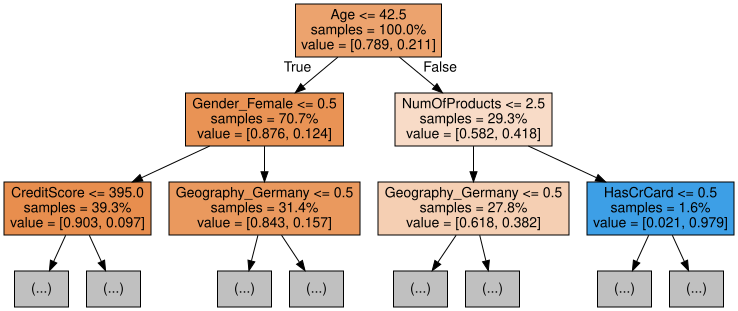

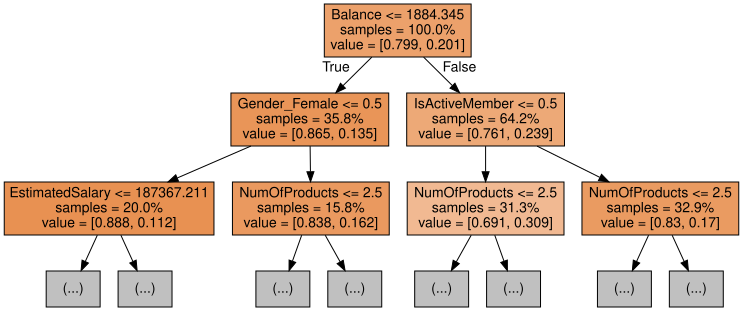

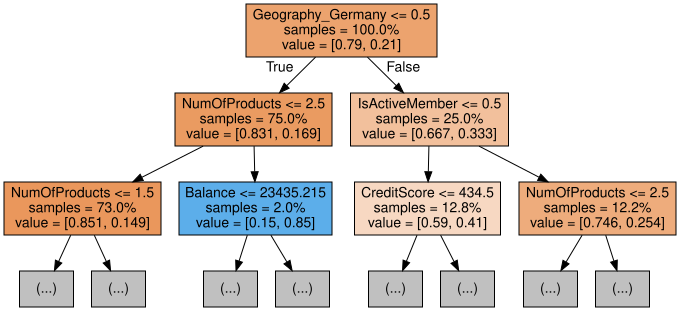

In [128]:
for i in range(3):
    tree = rf.estimators_[i]
    dot_data = export_graphviz(tree,
                               feature_names=X_train.columns,  
                               filled=True,  
                               max_depth=2, 
                               impurity=False, 
                               proportion=True)
    graph = graphviz.Source(dot_data)
    display(graph)